### Feature Set A: Patient Hormone ActivityTarget Feature: T3_Level (Continuous value representing Triiodothyronine hormone concentrations).

Skewness: -0.0033183747862981
Classification: Continuous, Normal
Range: 0.5 - 3.5


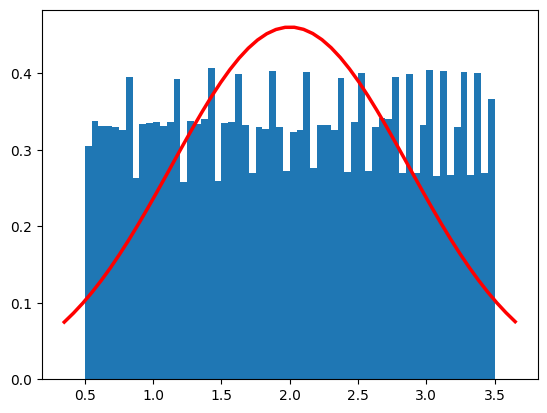

In [44]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats

data = pd.read_csv("thyroid_cancer_risk_data.csv")
t3_level = data["T3_Level"]

skewness = t3_level.skew()
loc, scale = stats.norm.fit(t3_level)

print(f"Skewness: {skewness}")
print("Classification: Continuous, Normal")
print(f"Range: {t3_level.min()} - {t3_level.max()}")

# Graph
plt.hist(t3_level, bins="auto", label="T3_Level Histogram", density=True)
x_min, x_max = plt.xlim()
x = np.linspace(x_min, x_max, 50)
pdf = stats.norm.pdf(x, loc=loc, scale=scale)
plt.plot(x, pdf, "r-", linewidth=2.5, label="Fitted Normal PDF")
plt.show()

### Feature Set B: Structural Anomaly DimensionsTarget Feature: Nodule_Size (Continuous measurements of cellular tissue growth).

Skewness: -0.004936761950607867
Classification: Continuous, Gamma
Range: 0.0 - 5.0


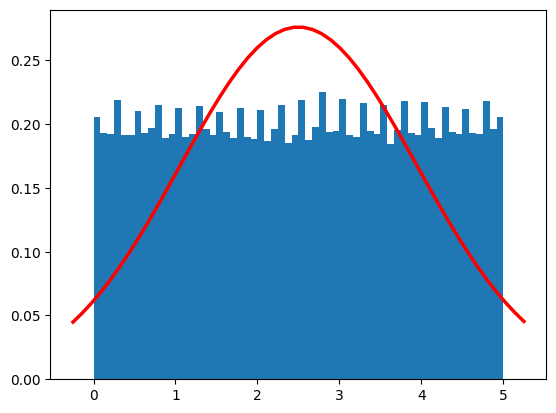

In [45]:
nodule_size = data["Nodule_Size"]

skewness = nodule_size.skew()

shape, location, scale = stats.gamma.fit(nodule_size)

print(f"Skewness: {skewness}")
print("Classification: Continuous, Gamma")
print(f"Range: {nodule_size.min()} - {nodule_size.max()}")

plt.hist(nodule_size, bins="auto", label="Nodule_Size Histogram", density=True)
x_min, x_max = plt.xlim()
x = np.linspace(x_min, x_max, 50)
pdf = stats.gamma.pdf(x, shape, location, scale)
plt.plot(x, pdf, "r-", linewidth=2.5, label="Fitted Gamma PDF")
plt.show()

### Feature Set C: Cumulative Medical ComorbiditiesFeature Setup: Generate a new feature named Risk_Factor_Count by writing a script that sums up how many independent binary lifestyle flags (Radiation_Exposure, Iodine_Deficiency, Smoking, Obesity) are marked as &quot;Yes&quot; for each patient record.

Skewness: 0    0.644348
dtype: float64
Classification: Discrete, Binomial
Range: 0 - 4


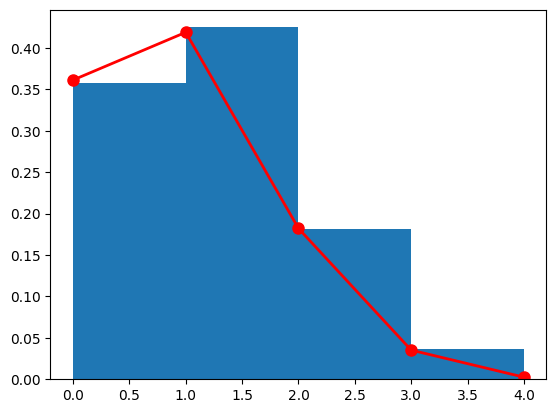

In [46]:
radiation_exposure = data["Radiation_Exposure"]
iodine_deficiency = data["Iodine_Deficiency"]
smoking = data["Smoking"]
obesity = data["Obesity"]

risk_factor_count = []

for i in range(len(data)):
    count = 0
    if radiation_exposure[i] == "Yes":
        count += 1
    if iodine_deficiency[i] == "Yes":
        count += 1
    if smoking[i] == "Yes":
        count += 1
    if obesity[i] == "Yes":
        count += 1
    risk_factor_count.append(count)


skewness = pd.DataFrame(risk_factor_count).skew()

print(f"Skewness: {skewness}")
print("Classification: Discrete, Binomial")
print(f"Range: {min(risk_factor_count)} - {max(risk_factor_count)}")


plt.hist(risk_factor_count, bins="auto", label="Risk_Factor_Count Histogram", density=True)
x_min, x_max = plt.xlim()
x = np.linspace(x_min, x_max, 50)

probability = np.mean(risk_factor_count) / 4
pmf_values = stats.binom.pmf(np.arange(0, 5), 4, probability)
plt.plot(np.arange(0, 5), pmf_values, "ro-", linewidth=2, markersize=8, label=f"Binomial PMF (n=4, p={probability:.2f})",)
plt.show()

### Feature Set D: Random Diagnostic TrialsFeature Setup: Group the final binary outcome column Diagnosis (Malignant vs Benign) into 5,000 independent chunks of exactly N=30 patients each. Count the total number of successful Malignant occurrences within each 30-patient subset.

Skewness: 0    0.230822
dtype: float64
Classification: Discrete, Binomial
Range: 0 - 18


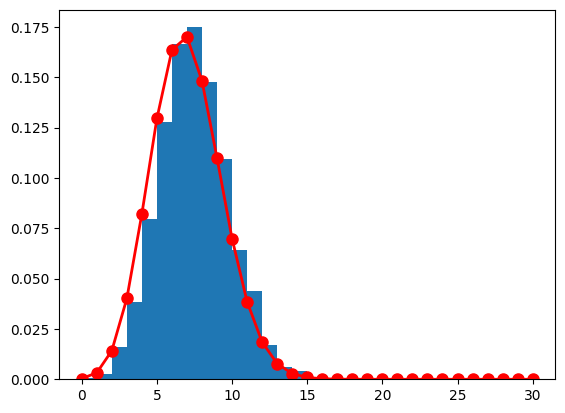

In [47]:
diagnosis_series = data["Diagnosis"].replace({"Malignant": 1, "Benign": 0})

chunk_size = 30
total_chunks = 5000

malignant_counts = []

for i in range(total_chunks):
    start = i * chunk_size
    end = start + chunk_size
    chunk = diagnosis_series.iloc[start:end]
    count = chunk.sum()
    malignant_counts.append(count)

skewness = pd.DataFrame(malignant_counts).skew()

print(f"Skewness: {skewness}")
print("Classification: Discrete, Binomial")
print(f"Range: {min(malignant_counts)} - {max(malignant_counts)}")


plt.hist(malignant_counts, bins="auto", label="Malignant_Counts Histogram", density=True)
x_min, x_max = plt.xlim()
x = np.linspace(x_min, x_max, 50)

probability = np.mean(malignant_counts) / chunk_size
pmf_values = stats.binom.pmf(np.arange(0, chunk_size + 1), chunk_size, probability)
plt.plot(np.arange(0, chunk_size + 1), pmf_values, "ro-", linewidth=2, markersize=8, label=f"Binomial PMF (n={chunk_size}, p={probability:.2f})")
plt.show()